In [67]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from curl_cffi import requests
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import talib as ta
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import pickle
from hmmlearn.hmm import GaussianHMM
import boto3
from dotenv import load_dotenv
import os
import seaborn as sns
sns.set_theme(style="whitegrid")

In [ ]:
# load_dotenv()
# S3_BUCKET_NAME=os.getenv("S3_BUCKET_NAME")
# s3 = boto3.client('s3')
# s3.download_file(Bucket=S3_BUCKET_NAME, Key='nifty_data.pkl', Filename='./tmp/nifty_data.pkl')
# with open("./tmp/nifty_data.pkl", "rb") as f:
#     data = pickle.load(f)
# data["data"].info()

In [ ]:
# session = requests.Session(impersonate="chrome")

In [ ]:
# ticker = "^NSEI"
# df_obj = yf.Ticker(ticker, session=session)
# data = df_obj.history(period="max", interval="1d")

In [2]:
# with open('../../data/nifty_data.pkl', 'wb') as f:
#     pickle.dump(data, f)

with open('/Users/gautamnaik/Developer/ai/gmmm_direction_prediction/data/nifty_data.pkl', 'rb') as f:
    data = pickle.load(f)

In [ ]:
# nifty_data = {
#     'data': data,
#     'metadata': {
#         'source': 'Yahoo Finance',
#         'ticker': '^NSEI',
#         'last_date': pd.to_datetime(data.index.max()).normalize()
#     }
# }

# with open('./tmp/nifty_data.pkl', 'wb') as f:
#     pickle.dump(nifty_data, f)

# s3.upload_file(Filename='./tmp/nifty_data.pkl', Bucket=S3_BUCKET_NAME, Key='nifty_data.pkl')

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4418 entries, 2007-09-17 00:00:00+05:30 to 2025-09-19 00:00:00+05:30
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          4418 non-null   float64
 1   High          4418 non-null   float64
 2   Low           4418 non-null   float64
 3   Close         4418 non-null   float64
 4   Volume        4418 non-null   int64  
 5   Dividends     4418 non-null   float64
 6   Stock Splits  4418 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 276.1 KB


In [38]:
df= data.copy()

In [39]:
df

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902,0,0.0,0.0
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195,0,0.0,0.0
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098,0,0.0,0.0
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805,0,0.0,0.0
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805,0,0.0,0.0
...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0


In [40]:
df['return_1d'] = df['Close'].pct_change()
df['return_5d'] = df['Close'].pct_change(5)
df['momentum_10d'] = ta.MOM(df['Close'], timeperiod=10)
df['ma_ratio'] = df['Close'] / ta.SMA(df['Close'], timeperiod=50)

# Risk Features
df['vol_10d'] = df['return_1d'].rolling(10).std()
df['vol_20d'] = df['return_1d'].rolling(20).std()
df['vol_ratio'] = df['vol_10d'] / df['vol_20d']
df['atr_14'] = ta.ATR(df['High'], df['Low'], df['Close'], timeperiod=14) / df['Close']

# Stress Features
df['drawdown'] = df['Close'] / df['Close'].cummax() - 1

# Exhaustion Features
df['rsi_14'] = ta.RSI(df['Close'], timeperiod=14)

In [41]:
window = 252  # ~1 year of trading days
for col in ['return_1d', 'return_5d', 'momentum_10d', 'ma_ratio', 
            'vol_10d', 'vol_20d', 'vol_ratio', 'atr_14', 
            'drawdown', 'rsi_14']:
    df[f'{col}_z'] = (df[col] - df[col].rolling(window).mean()) / df[col].rolling(window).std()

In [ ]:
zscore_cols = [col for col in df.columns if col.endswith('_z')]

In [43]:
df

,Open,High,Low,Close,Volume,Dividends,Stock Splits,return_1d,return_5d,momentum_10d,...,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z
Date,,,,,,,,,,,,,,,,,,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902,0,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195,0,0.0,0.0,0.011469,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098,0,0.0,0.0,0.040946,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805,0,0.0,0.0,0.003212,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805,0,0.0,0.0,0.018957,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0,-0.001784,0.011950,444.148438,...,-0.220865,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0,0.006777,0.014898,659.500000,...,0.810716,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0,0.003611,0.014301,615.199219,...,0.438974,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710


In [44]:
features_orig = df[zscore_cols].dropna()

In [45]:
features_orig

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z
Date,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.868366,-0.034404,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185
2008-12-08 00:00:00+05:30,1.022532,0.851616,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849
2008-12-10 00:00:00+05:30,1.951083,1.918223,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186
2008-12-11 00:00:00+05:30,-0.019707,1.859247,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967
2008-12-12 00:00:00+05:30,0.098432,0.996233,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594
...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.220865,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694
2025-09-16 00:00:00+05:30,0.810716,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401
2025-09-17 00:00:00+05:30,0.438974,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710


In [52]:
features = features_orig.copy()

In [54]:
scaler = StandardScaler()
X = scaler.fit_transform(features)

In [55]:
best_bic = np.inf
best_model = None
clusters_count = None
for K in range(2, 8):
    for cov_type in ['full', 'tied', 'diag', 'spherical']:
        model = GaussianHMM(n_components=K, covariance_type=cov_type, n_iter=2000)
        model.fit(X)
        logL = model.score(X)
        n_params = K*(K-1) + K*X.shape[1]*2  # rough estimate
        bic = n_params * np.log(len(X)) - 2*logL
        if bic < best_bic:
            best_bic = bic
            best_model = model
            clusters_count = K

In [56]:
features['hmm_cluster'] = best_model.predict(X)

In [57]:
best_model.score(X)

-22828.56566808112

In [64]:
features

,return_1d_z,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,hmm_cluster
Date,,,,,,,,,,,
2008-12-05 00:00:00+05:30,-0.868366,-0.034404,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,1
2008-12-08 00:00:00+05:30,1.022532,0.851616,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,1
2008-12-10 00:00:00+05:30,1.951083,1.918223,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,1
2008-12-11 00:00:00+05:30,-0.019707,1.859247,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,1
2008-12-12 00:00:00+05:30,0.098432,0.996233,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,1
...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,-0.220865,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,0
2025-09-16 00:00:00+05:30,0.810716,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,0
2025-09-17 00:00:00+05:30,0.438974,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,0


In [62]:
df_merged = df.join(features["hmm_cluster" ], how='right')

In [63]:
df_merged

,Open,High,Low,Close,Volume,Dividends,Stock Splits,return_1d,return_5d,momentum_10d,...,return_5d_z,momentum_10d_z,ma_ratio_z,vol_10d_z,vol_20d_z,vol_ratio_z,atr_14_z,drawdown_z,rsi_14_z,hmm_cluster
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-05 00:00:00+05:30,2786.649902,2821.149902,2701.350098,2714.399902,0,0.0,0.0,-0.026399,-0.014773,161.250000,...,-0.034404,0.818804,-0.893201,0.466628,0.875523,-0.442671,1.421776,-1.959277,-0.161185,1
2008-12-08 00:00:00+05:30,2714.699951,2861.550049,2714.699951,2784.000000,0,0.0,0.0,0.025641,0.037683,90.550049,...,0.851616,0.612411,-0.566939,0.135168,0.856711,-0.966425,1.300708,-1.868706,0.143849,1
2008-12-10 00:00:00+05:30,2785.699951,2940.149902,2785.699951,2928.250000,0,0.0,0.0,0.051814,0.101757,220.000000,...,1.918223,0.980275,0.009230,0.467282,0.987278,-0.576041,1.109375,-1.703545,0.703186,1
2008-12-11 00:00:00+05:30,2934.050049,2945.300049,2861.550049,2920.149902,0,0.0,0.0,-0.002766,0.099268,266.149902,...,1.859247,1.105420,0.063236,0.355722,0.715847,-0.419203,0.994198,-1.696675,0.668967,1
2008-12-12 00:00:00+05:30,2915.350098,2936.800049,2812.550049,2921.350098,0,0.0,0.0,0.000411,0.047830,169.100098,...,0.996233,0.820280,0.153577,0.229341,0.375358,-0.153147,0.944607,-1.681398,0.675594,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,185400,0.0,0.0,-0.001784,0.011950,444.148438,...,0.597368,0.736534,0.223451,-1.784797,-1.148942,-2.198674,-1.954375,0.818201,0.815694,0
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,240100,0.0,0.0,0.006777,0.014898,659.500000,...,0.741292,1.078019,0.461394,-1.743319,-1.254367,-1.996493,-1.949217,1.001474,1.220401,0
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,268900,0.0,0.0,0.003611,0.014301,615.199219,...,0.709718,1.002250,0.591904,-1.780614,-1.256610,-2.101944,-2.051370,1.107109,1.414710,0


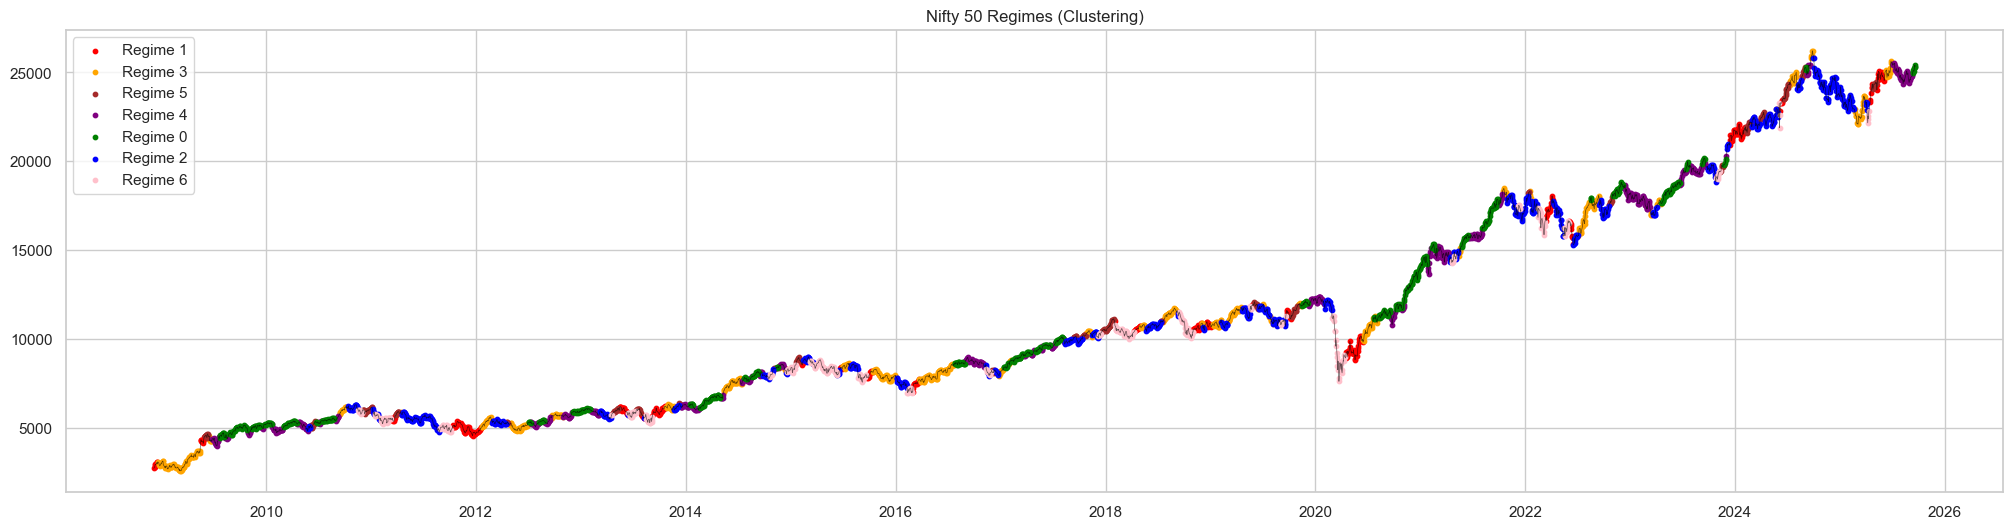

In [68]:
plt.figure(figsize=(25,6))
colors = {0:"green", 1:"red", 2:"blue", 3:"orange", 4:"purple", 5:"brown", 6:"pink", 7:"gray", 8:"cyan", 9:"magenta"}
for c in df_merged['hmm_cluster'].dropna().unique():
    mask = df_merged['hmm_cluster'] == c
    plt.scatter(df_merged.index[mask], df_merged['Close'][mask], label=f"Regime {c}", s=10, c=colors[c])
plt.plot(df_merged.index, df_merged['Close'], color='black', linewidth=0.5, alpha=0.6)
plt.title("Nifty 50 Regimes (Clustering)")
plt.legend()
plt.show()

In [103]:
import ruptures as rpt

signal = df_merged[zscore_cols].dropna().values
algo = rpt.KernelCPD(kernel="rbf").fit(signal)
breaks = algo.predict(pen=12)  # or specify n_bkps

In [108]:
X_pca = PCA(n_components=6).fit_transform(df_merged[zscore_cols].dropna())

algorithm = rpt.KernelCPD(kernel="rbf").fit(X_pca)
breaks = algorithm.predict(pen=12)


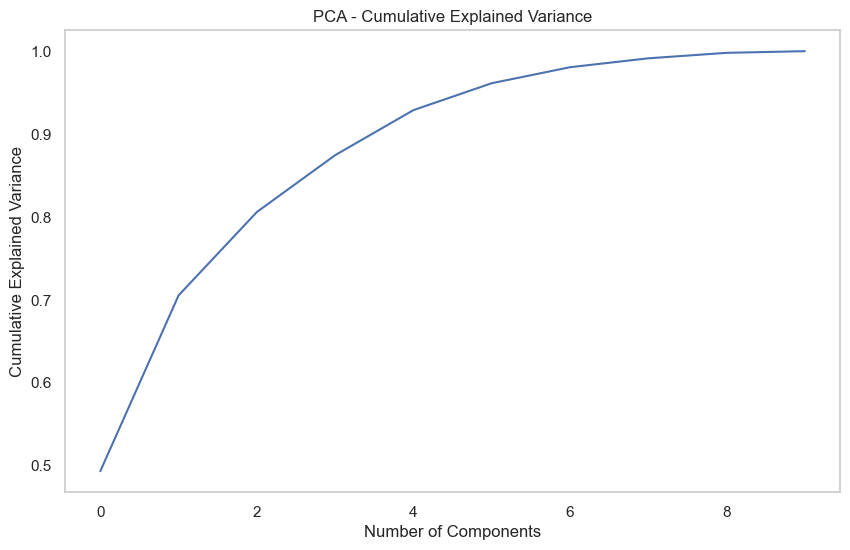

In [107]:
# plot cumulative explained variance
plt.figure(figsize=(10,6))
plt.plot(np.cumsum(PCA().fit(df_merged[zscore_cols].dropna()).explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.grid()
plt.show()

In [109]:
# merge change points with original dataframe
df_merged['change_point'] = 0
df_merged.loc[df_merged.index[breaks[:-1]], 'change_point'] = 1

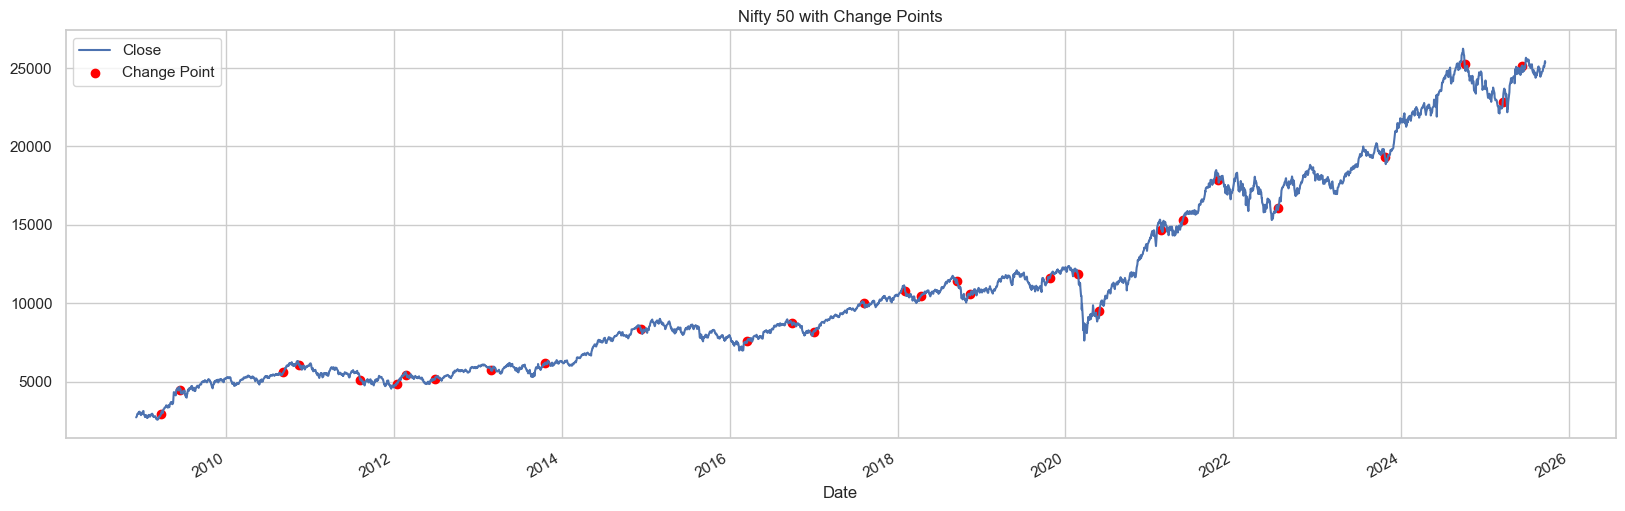

In [110]:
df_merged["Close"].plot(figsize=(20,6))
# plot change points
plt.scatter(df_merged.index[df_merged['change_point'] == 1], df_merged['Close'][df_merged['change_point'] == 1], color='red', marker='o', label='Change Point')
plt.title("Nifty 50 with Change Points")
plt.legend()

In [59]:
features['dbscan_cluster'].value_counts()

dbscan_cluster
 0    2565
-1      25
Name: count, dtype: int64

In [38]:
final = df_merged["hmm_cluster"]

In [39]:
final = final.reset_index()

In [40]:
final["Date"] = pd.to_datetime(final['Date'])
# remove timezone info
final['Date'] = final['Date'].dt.tz_localize(None)

In [41]:
final

,Date,hmm_cluster
0,2013-01-21,2
1,2013-01-22,2
2,2013-01-23,2
3,2013-01-24,2
4,2013-01-25,2
...,...,...
3108,2025-09-15,1
3109,2025-09-16,1
3110,2025-09-17,1
3111,2025-09-18,1


In [84]:
# with open("../../data/nifty_regimes.pkl", 'wb') as f:
#     pickle.dump(final, f)

with open("../../data/nifty_regimes.pkl", 'rb') as f:
    final = pickle.load(f)

In [42]:
final=final.set_index('Date')

In [43]:
final

,hmm_cluster
Date,
2013-01-21,2
2013-01-22,2
2013-01-23,2
2013-01-24,2
2013-01-25,2
...,...
2025-09-15,1
2025-09-16,1
2025-09-17,1


In [44]:
full_idx = pd.date_range(final.index.min(), final.index.max(), freq="D")
final = final.reindex(full_idx)

In [45]:
full_idx

DatetimeIndex(['2013-01-21', '2013-01-22', '2013-01-23', '2013-01-24',
               '2013-01-25', '2013-01-26', '2013-01-27', '2013-01-28',
               '2013-01-29', '2013-01-30',
               ...
               '2025-09-10', '2025-09-11', '2025-09-12', '2025-09-13',
               '2025-09-14', '2025-09-15', '2025-09-16', '2025-09-17',
               '2025-09-18', '2025-09-19'],
              dtype='datetime64[ns]', length=4625, freq='D')

In [46]:
final=final.bfill()

In [47]:
final.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4625 entries, 2013-01-21 to 2025-09-19
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hmm_cluster  4625 non-null   float64
dtypes: float64(1)
memory usage: 72.3 KB


In [48]:
final.loc['2016-08-12 00:00:00']

hmm_cluster    2.0
Name: 2016-08-12 00:00:00, dtype: float64

In [50]:
with open("../../data/nifty_regimes_m.pkl", 'wb') as f:
    pickle.dump(final, f)

# with open("../../data/nifty_regimes_m.pkl", 'rb') as f:
#     final = pickle.load(f)

In [49]:
final.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4625 entries, 2013-01-21 to 2025-09-19
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hmm_cluster  4625 non-null   float64
dtypes: float64(1)
memory usage: 201.3 KB


In [10]:
df.columns

Index(['Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits',
       'return_1d', 'return_5d', 'momentum_10d', 'ma_ratio', 'vol_10d',
       'vol_20d', 'vol_ratio', 'atr_14', 'drawdown', 'rsi_14', 'vol_zscore',
       'obv'],
      dtype='object')

In [18]:
df=df.drop(columns=['Dividends', 'Stock Splits', 'Volume'])

In [19]:
df

,Open,High,Low,Close
Date,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805
...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000


In [ ]:
df['return_5d'] = df['Close'].pct_change(5)
df["return_10d"] = df['Close'].pct_change(10)
df['return_20d'] = df['Close'].pct_change(20)
df['momentum_5d'] = ta.MOM(df['Close'], timeperiod=5)
df['momentum_10d'] = ta.MOM(df['Close'], timeperiod=10)
df['momentum_20d'] = ta.MOM(df['Close'], timeperiod=20)

In [23]:
df

,Open,High,Low,Close,return_5d,roc_5d,momentum_5d,momentum_10d
Date,,,,,,,,
2007-09-17 00:00:00+05:30,4518.450195,4549.049805,4482.850098,4494.649902,NaN,NaN,NaN,NaN
2007-09-18 00:00:00+05:30,4494.100098,4551.799805,4481.549805,4546.200195,NaN,NaN,NaN,NaN
2007-09-19 00:00:00+05:30,4550.250000,4739.000000,4550.250000,4732.350098,NaN,NaN,NaN,NaN
2007-09-20 00:00:00+05:30,4734.850098,4760.850098,4721.149902,4747.549805,NaN,NaN,NaN,NaN
2007-09-21 00:00:00+05:30,4752.950195,4855.700195,4733.700195,4837.549805,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
2025-09-15 00:00:00+05:30,25118.900391,25138.449219,25048.750000,25069.199219,0.011950,1.195039,296.048828,444.148438
2025-09-16 00:00:00+05:30,25073.599609,25261.400391,25070.449219,25239.099609,0.014898,1.489831,370.500000,659.500000
2025-09-17 00:00:00+05:30,25276.599609,25346.500000,25275.349609,25330.250000,0.014301,1.430140,357.150391,615.199219


In [4]:
s3.download_file(Bucket=S3_BUCKET_NAME, Key='nifty_regime_model.pkl', Filename='/tmp/nifty_regime_model.pkl')

with open('/tmp/nifty_regime_model.pkl', 'rb') as f:
    model_dict = pickle.load(f)

/opt/miniconda3/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [5]:
model_dict

{'model': GaussianHMM(covariance_type='full', n_components=7, n_iter=2000),
 'scaler': StandardScaler(),
 'clusters_count': 7}

In [6]:
model = model_dict['model']
scaler = model_dict['scaler']

In [9]:
ticker = "^NSEI"
df_obj = yf.Ticker(ticker, session=session)
data = df_obj.history(period="3mo", interval="1d")

In [12]:
def prepare_features(df):
    df['return_1d'] = df['Close'].pct_change()
    df['return_5d'] = df['Close'].pct_change(5)
    df['momentum_10d'] = ta.MOM(df['Close'], timeperiod=10)
    df['ma_ratio'] = df['Close'] / ta.SMA(df['Close'], timeperiod=50)

    # Risk Features
    df['vol_10d'] = df['return_1d'].rolling(10).std()
    df['vol_20d'] = df['return_1d'].rolling(20).std()
    df['vol_ratio'] = df['vol_10d'] / df['vol_20d']
    df['atr_14'] = ta.ATR(df['High'], df['Low'], df['Close'], timeperiod=14) / df['Close']

    # Stress Features
    df['drawdown'] = df['Close'] / df['Close'].cummax() - 1

    # Exhaustion Features
    df['rsi_14'] = ta.RSI(df['Close'], timeperiod=14)


    # Collect feature set
    features_orig = df[['return_1d', 'return_5d', 'momentum_10d', 'ma_ratio',
                'vol_10d', 'vol_20d', 'vol_ratio', 'atr_14',
                'drawdown', 'rsi_14']].dropna()
    
    return features_orig

In [10]:
data

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-07-14 00:00:00+05:30,25149.500000,25151.099609,25001.949219,25082.300781,259500,0.0,0.0
2025-07-15 00:00:00+05:30,25089.500000,25245.199219,25088.449219,25195.800781,241300,0.0,0.0
2025-07-16 00:00:00+05:30,25196.599609,25255.300781,25121.050781,25212.050781,228800,0.0,0.0
2025-07-17 00:00:00+05:30,25230.750000,25238.349609,25101.000000,25111.449219,243400,0.0,0.0
2025-07-18 00:00:00+05:30,25108.550781,25144.599609,24918.650391,24968.400391,317000,0.0,0.0
...,...,...,...,...,...,...,...
2025-10-07 00:00:00+05:30,25085.300781,25220.900391,25076.300781,25108.300781,288000,0.0,0.0
2025-10-08 00:00:00+05:30,25079.750000,25192.500000,25008.500000,25046.150391,227400,0.0,0.0
2025-10-09 00:00:00+05:30,25074.300781,25199.250000,25024.300781,25181.800781,286300,0.0,0.0


In [13]:
processed_features = prepare_features(data)

In [14]:
processed_features

,return_1d,return_5d,momentum_10d,ma_ratio,vol_10d,vol_20d,vol_ratio,atr_14,drawdown,rsi_14
Date,,,,,,,,,,
2025-09-23 00:00:00+05:30,-0.001303,-0.002758,300.900391,1.011538,0.003939,0.004892,0.805132,0.006741,-0.009995,56.675332
2025-09-24 00:00:00+05:30,-0.004474,-0.010791,83.800781,1.007033,0.004156,0.004373,0.950309,0.006692,-0.014424,52.063109
2025-09-25 00:00:00+05:30,-0.006627,-0.020955,-114.650391,1.000605,0.004677,0.004177,1.119744,0.006871,-0.020955,46.104459
2025-09-26 00:00:00+05:30,-0.009487,-0.026547,-459.300781,0.991556,0.005126,0.004705,1.089550,0.007198,-0.030244,39.228250
2025-09-29 00:00:00+05:30,-0.000803,-0.022516,-434.298828,0.991140,0.005136,0.004352,1.180260,0.007226,-0.031022,38.707017
2025-09-30 00:00:00+05:30,-0.000966,-0.022186,-628.000000,0.990467,0.004211,0.004336,0.971071,0.007135,-0.031958,38.052454
2025-10-01 00:00:00+05:30,0.009150,-0.008804,-493.949219,0.999735,0.005323,0.004642,1.146634,0.007319,-0.023101,47.157986
2025-10-03 00:00:00+05:30,0.002333,0.000137,-529.349609,1.002202,0.005179,0.004664,1.110316,0.007231,-0.020821,49.226141
2025-10-06 00:00:00+05:30,0.007367,0.017155,-249.400391,1.009701,0.005920,0.004922,1.202768,0.007276,-0.013607,55.201991


In [15]:
processed_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 14 entries, 2025-09-23 00:00:00+05:30 to 2025-10-13 00:00:00+05:30
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   return_1d     14 non-null     float64
 1   return_5d     14 non-null     float64
 2   momentum_10d  14 non-null     float64
 3   ma_ratio      14 non-null     float64
 4   vol_10d       14 non-null     float64
 5   vol_20d       14 non-null     float64
 6   vol_ratio     14 non-null     float64
 7   atr_14        14 non-null     float64
 8   drawdown      14 non-null     float64
 9   rsi_14        14 non-null     float64
dtypes: float64(10)
memory usage: 1.2 KB


In [18]:
processed_features.shape

(14, 10)

In [16]:
X_scaled = scaler.transform(processed_features)

In [24]:
model.predict(X_scaled[-1].reshape(1, -1))[0]

4

In [23]:
model.predict(X_scaled)

array([4, 1, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6])

In [19]:
pd.DataFrame(X_scaled, columns=processed_features.columns).round(2).head(5)

,return_1d,return_5d,momentum_10d,ma_ratio,vol_10d,vol_20d,vol_ratio,atr_14,drawdown,rsi_14
0,-0.13,-0.17,0.68,0.05,-0.91,-0.86,-0.87,-0.95,0.80,0.22
1,-0.38,-0.44,0.11,-0.04,-0.88,-0.94,-0.14,-0.95,0.76,-0.14
2,-0.54,-0.79,-0.42,-0.16,-0.81,-0.96,0.72,-0.93,0.70,-0.62
3,-0.76,-0.98,-1.34,-0.33,-0.75,-0.89,0.57,-0.90,0.62,-1.17
4,-0.09,-0.85,-1.27,-0.34,-0.74,-0.94,1.03,-0.90,0.61,-1.21
